# 4. Fase prescriptiva: Modelo de optimización de localización

Las predicciones generadas por el modelo predictivo de ocurrencia sirven como insumo directo para la demanda ponderada del modelo de optimización, conectando ambas etapas de la metodología. El modelo de optimización seleccionado es el Problema de Localización de Máxima Cobertura (MCLP, por sus siglas en inglés), debido a que la información de la red vial es estática y no direccionada, y el objetivo es maximizar la demanda (riesgo de accidente) cubierta dentro de un umbral de respuesta. El procedimiento comprende la definición de ubicaciones candidatas, la identificación de segmentos de alto riesgo, la resolución del modelo mediante IBM CPLEX y la evaluación espacial de las soluciones obtenidas.

## 1. Configuración y librerías

In [1]:
import sys
import subprocess

# Diccionario con el nombre del módulo al importar y el nombre del paquete en pip
librerias_requeridas = {
    'pandas': 'pandas',
    'geopandas': 'geopandas',
    'matplotlib': 'matplotlib',
    'docplex': 'docplex'
}

# Verificación e instalación dinámica
for modulo, paquete in librerias_requeridas.items():
    try:
        __import__(modulo)
    except ImportError:
        print(f"La librería '{modulo}' no se encontró. Iniciando instalación...")
        # Ejecuta el comando pip install usando el ejecutable actual de Python
        subprocess.check_call([sys.executable, "-m", "pip", "install", paquete])
        print(f"{modulo} se instaló exitosamente.")

# Imports estándar
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import time
from docplex.mp.model import Model
import os
import json

# Configuración del notebook
pd.set_option('display.max_columns', None)

print("Configuración inicial completada. Todo listo para trabajar.")

Configuración inicial completada. Todo listo para trabajar.


## 2. Lectura de datos

In [2]:
# Cargar las predicciones del RF calibrado
gdf_pred = gpd.read_parquet("Generados/predicciones.parquet")
print("Predicciones del RF calibrado cargadas")

# Cargar la red vial de Aguascalientes
gdf_rnc = gpd.read_parquet("Generados/rnc_ags.parquet")
print("Red vial cargada")

# Umbrales de clasificación
archivo_umbral = 'umbral_config.json'
with open(archivo_umbral, 'r') as f:
        config_umbral = json.load(f)
umbral = config_umbral["umbral_calibrado"]
print(f"Umbral de clasificación cargado: {umbral}")

Predicciones del RF calibrado cargadas
Red vial cargada
Umbral de clasificación cargado: 0.19187358916478556


## 3. Conjunto de candidatos de ubicaciones

El MCLP requiere de dos conjuntos fundamentales: el conjunto de puntos de demanda ($I$) y el conjunto de posibles ubicaciones de instalaciones ($J$). Para definir el conjunto de ubicaciones candidatas, se aplicaron varios filtros sobre la red vial de Aguascalientes, considerando características operativas de accesibilidad y seguridad:

- Carriles $> 2$.
- Longitud $> 100$ m.
- Nivel $= 0$.
- Sinuosidad $< 1.2$.
- Exclusión de calles privadas y glorietas.
- Velocidad $\geq 30$ km/h.

Adicionalmente, para evitar redundancias en la segmentación de la red, solo se conservaron los segmentos extremos de cada arista base. Los tramos seleccionados constituyen las ubicaciones candidatas, cuya posición de instalación se representa posteriormente mediante sus puntos medios.

In [3]:
# FILTRADO INICIAL POR CARACTERÍSTICAS DE LA RED VIAL
filtrados = gdf_rnc[
    (gdf_rnc["CARRILES"] > 2) &
    (gdf_rnc["LONGITUD"] > 100) &
    (gdf_rnc["NIVEL"] == 0) &
    (gdf_rnc["SINUOSIDAD"] < 1.2) &
    (gdf_rnc["PRIVADA"] != 1) &
    (gdf_rnc["GLORIETA"] != 1) &
    (gdf_rnc["VELOCIDAD"] >= 30)
].copy()

# FILTRADO POR EXTREMOS
# Separar el ID_RED por el guion bajo
# Si no hay '_', expand=True pondrá la arista en la primera columna y None en la segunda
partes = filtrados['ID_RED'].str.split('_', expand=True)
filtrados['ARISTA_BASE'] = partes[0]

# Si la segunda columna es None/NaN, significa que no tenía '_', así que le asignamos un '1'
filtrados['SUFIJO'] = partes[1].fillna('1')

# Consversión del sufijo a entero de forma segura
filtrados['SUFIJO'] = filtrados['SUFIJO'].astype(int)

# Ordenar el DataFrame por la arista base y el número de sufijo
filtrados = filtrados.sort_values(by=['ARISTA_BASE', 'SUFIJO'])

# Aplicar la lógica de quedarnos con los extremos (primero y último)
es_primero = ~filtrados.duplicated(subset=['ARISTA_BASE'], keep='first')
es_ultimo = ~filtrados.duplicated(subset=['ARISTA_BASE'], keep='last')
resultado_final = filtrados[es_primero | es_ultimo]
candidatos = resultado_final.filter(items=['ID_RED', 'geometry'])
print(f"Numero de candidatos: {len(candidatos)}, Numero de aristas en rnc: {len(gdf_rnc)}")

Numero de candidatos: 5475, Numero de aristas en rnc: 63010


Aristas descartadas: 57535
Aristas candidatos: 5475


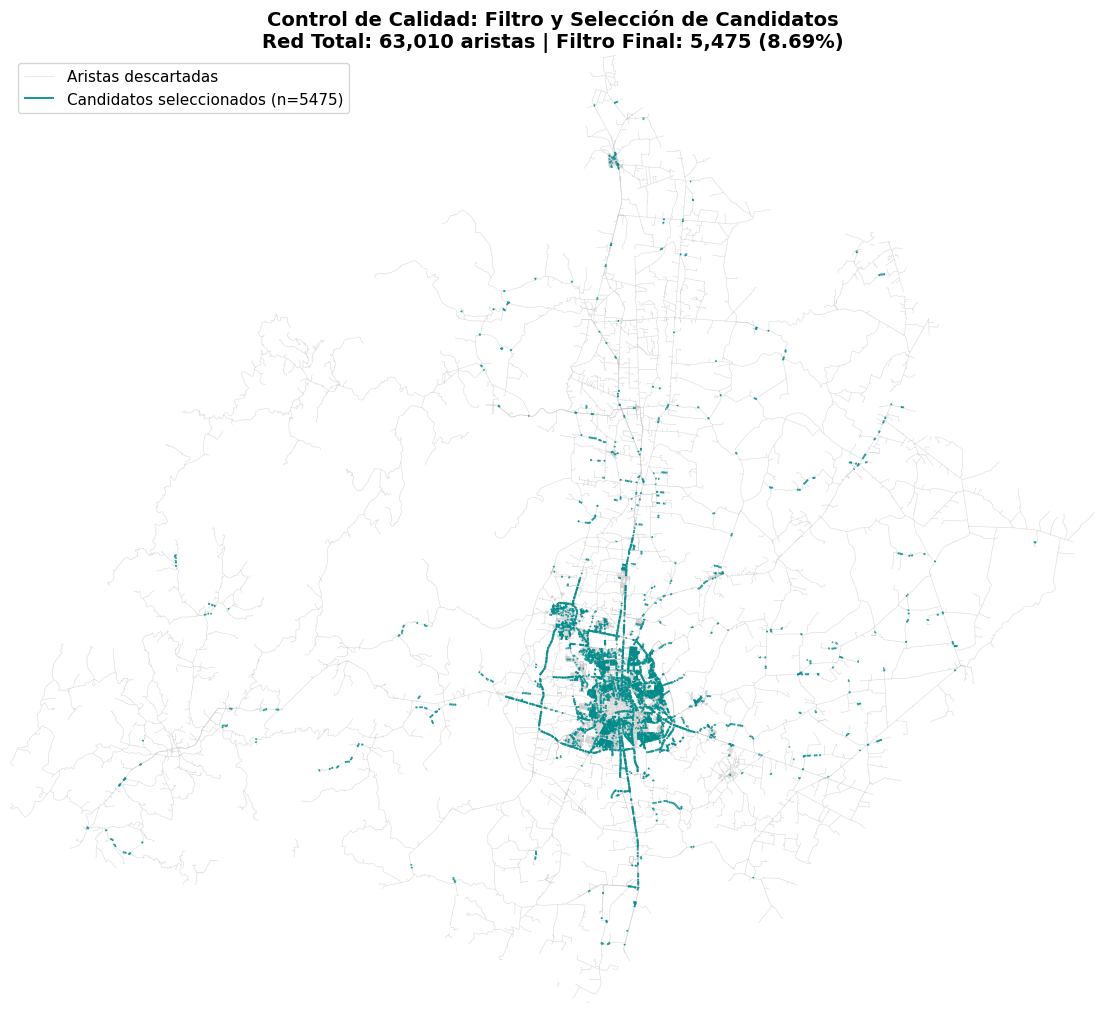

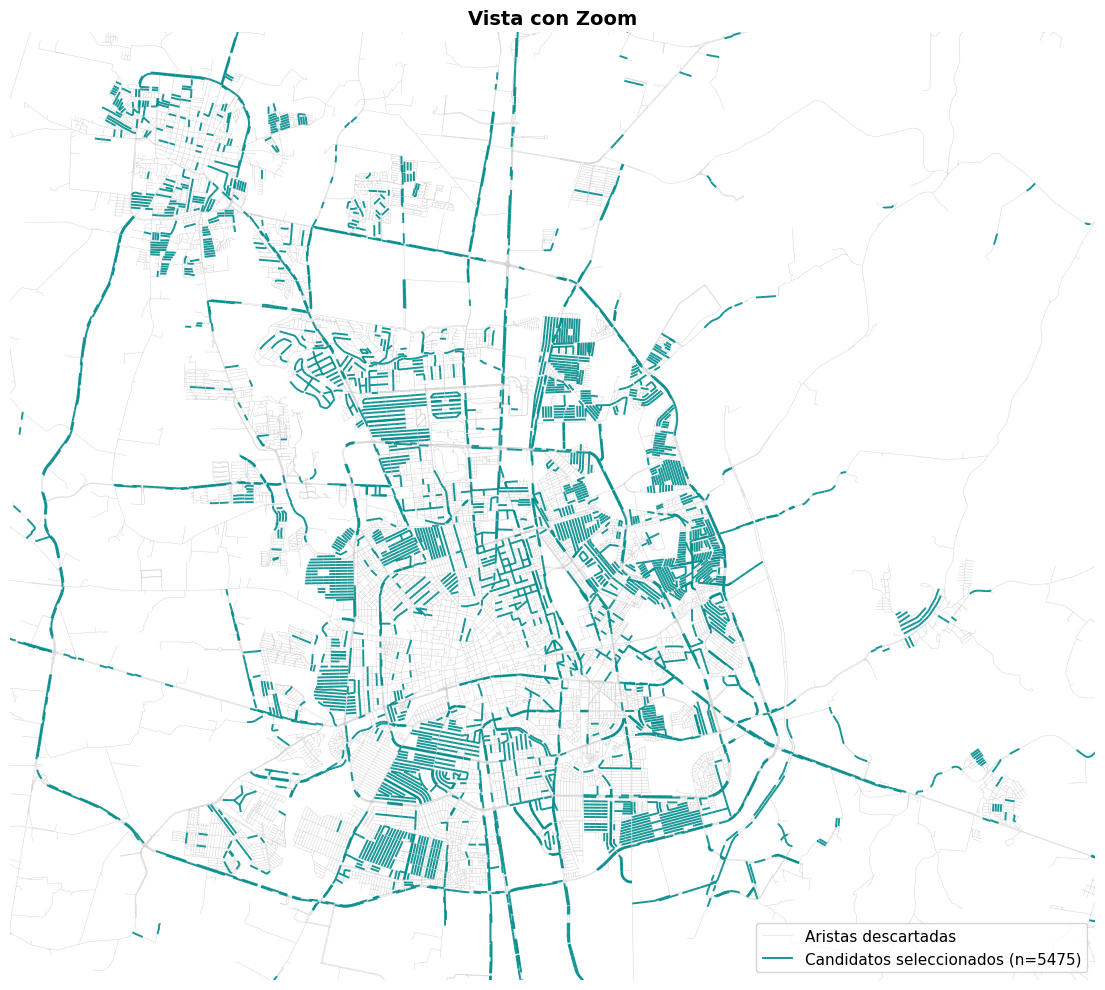

In [4]:
# GRÁFICO DE CONTROL DE CALIDAD: ARISTAS CONSIDERADAS VS NO CONSIDERADAS
aristas_no_consideradas = gdf_rnc[~gdf_rnc['ID_RED'].isin(candidatos['ID_RED'])]

print(f"Aristas descartadas: {len(aristas_no_consideradas)}")
print(f"Aristas candidatos: {len(candidatos)}")

# MAPA GENERAL COMPLETO
fig1, ax1 = plt.subplots(figsize=(14, 14))

# Capas
aristas_no_consideradas.plot(ax=ax1, color='silver', linewidth=0.4, alpha=0.6, label='Aristas descartadas')
candidatos.plot(ax=ax1, color='darkcyan', linewidth=1.4, alpha=0.9, label=f'Candidatos seleccionados (n={len(candidatos)})')

# Configuración
ax1.set_title(
    f"Control de Calidad: Filtro y Selección de Candidatos\n"
    f"Red Total: {len(gdf_rnc):,} aristas | Filtro Final: {len(candidatos):,} ({len(candidatos)/len(gdf_rnc):.2%})", 
    fontsize=14, fontweight='bold'
)

# Leyenda y límites
handles, labels = ax1.get_legend_handles_labels()
unique_labels = dict(zip(labels, handles))
ax1.legend(unique_labels.values(), unique_labels.keys(), loc='upper left', fontsize=11)
ax1.axis('off')

minx, miny, maxx, maxy = gdf_rnc.total_bounds
ax1.set_xlim(minx, maxx)
ax1.set_ylim(miny, maxy)

plt.show(fig1)

# MAPA CON ZOOM
fig2, ax2 = plt.subplots(figsize=(14, 14))

# Capas
aristas_no_consideradas.plot(ax=ax2, color='silver', linewidth=0.4, alpha=0.6, label='Aristas descartadas')
candidatos.plot(ax=ax2, color='darkcyan', linewidth=1.4, alpha=0.9, label=f'Candidatos seleccionados (n={len(candidatos)})')

# Configuración
ax2.set_title("Vista con Zoom", fontsize=14, fontweight='bold')
ax2.axis('off')

# Parámetros previamente definidos
factor_zoom = 0.18
desplazar_x = 0.073  
desplazar_y = -0.16 

# Calcular el ancho y alto original
ancho_total = maxx - minx
alto_total = maxy - miny

# Calcular el centro original y aplicarle el desplazamiento
centro_x = ((minx + maxx) / 2) + (ancho_total * desplazar_x)
centro_y = ((miny + maxy) / 2) + (alto_total * desplazar_y)

# Calcular el tamaño de la ventana de zoom
ancho_zoom = ancho_total * factor_zoom
alto_zoom = alto_total * factor_zoom

# Aplicar los nuevos límites a los ejes para hacer el "zoom in"
ax2.set_xlim(centro_x - (ancho_zoom / 2), centro_x + (ancho_zoom / 2))
ax2.set_ylim(centro_y - (alto_zoom / 2), centro_y + (alto_zoom / 2))

# Leyenda del zoom
handles2, labels2 = ax2.get_legend_handles_labels()
unique_labels2 = dict(zip(labels2, handles2))
ax2.legend(unique_labels2.values(), unique_labels2.keys(), loc='lower right', fontsize=11)

plt.show(fig2)

## 4. Solución del MCLP

Para cada instancia de prueba se identifican los segmentos de la red cuya probabilidad de accidente supera el umbral de clasificación de riesgo ($\tau$). Estos constituyen el conjunto de puntos de demanda ($I$).

### 4.1 Reducción de candidatos por cobertura

Para reducir la complejidad computacional, para cada instancia y cada cobertura se excluyen aquellos candidatos que no cubren ningún punto de demanda. Para ello, se generan buffers alrededor de los puntos medios de los segmentos candidatos y se realiza una intersección espacial con las aristas activas, utilizando procesamiento por lotes para reducir el consumo de memoria.

Su eliminación no afecta a la optimalidad y disminuye significativamente el espacio de candidatos, reduciendo consigo el tiempo de resolución del problema.

In [5]:
def reduccion_candidatos(
    id_instancia: str,
    umbral: float,
    radio_cobertura: float,
    preds: gpd.GeoDataFrame,
    candidatos: gpd.GeoDataFrame
) -> tuple[set[int], dict[int, list[int]], gpd.GeoDataFrame, float]:
    """
    Reduce el número de candidatos espaciales para cubrir aristas activas de la red vial,
    mediante buffers alrededor de puntos medios y cruces espaciales por lotes.

    Parámetros
    ----------
    `id_instancia`: Nombre de la columna en `preds` 
        que contiene las probabilidades de la franja temporal.
    `umbral`: Valor de corte para seleccionar aristas activas 
        (probabilidad > umbral).
    `radio_cobertura`: Radio del buffer alrededor de cada candidato 
        (en unidades del CRS proyectado).
    `preds`: GeoDataFrame con predicciones por arista de la red vial.
        Debe incluir:
        - 'ID_RED'
        - columna de probabilidades `id_instancia`
        - geometría de las aristas.
    `candidatos`: GeoDataFrame con geometría de aristas candidatas 
        (toda la red vial).

    Retorna
    -------
    `candidatos_utiles`: Conjunto de índices de candidatos que cubren 
        al menos una arista activa.
    `candidatos_que_cubren`: Diccionario que mapea cada índice de 
        arista activa a la lista de candidatos que la cubren.
    `aristas_activas`: Subconjunto de `preds` con las aristas activas 
        (probabilidad > umbral).
    `tiempo`: Tiempo total de ejecución en segundos.
    """
    start_time = time.time()

    preds_proj = preds.to_crs(preds.estimate_utm_crs())
    candidatos_proj = candidatos.to_crs(preds_proj.crs)

    # Aristas "encendidas" (Columnas de la matriz)
    aristas_activas = preds_proj[preds_proj[id_instancia] > umbral].copy()
    num_aristas = len(aristas_activas)

    # Puntos medios las 62,000 aristas
    print("\nGenerando puntos medios y buffers...")
    puntos_medios = candidatos_proj.geometry.interpolate(0.5, normalized=True)

    # Buffers alrededor de los puntos medios
    buffers_candidatos = puntos_medios.buffer(radio_cobertura)
    candidatos_gdf = gpd.GeoDataFrame(geometry=buffers_candidatos, crs=preds_proj.crs)
    candidatos_gdf['id_candidato'] = candidatos_gdf.index

    # Aristas activas respetando el índice original
    activas_gdf = gpd.GeoDataFrame(geometry=aristas_activas.geometry, crs=preds_proj.crs)
    activas_gdf['id_arista_activa'] = activas_gdf.index

    # Cruce espacial por Lotes para evitar colapso de RAM
    print("Calculando intersecciones espaciales por lotes (sjoin)...")

    # Inicializamos el diccionario asegurando que todas las aristas activas estén presentes
    candidatos_que_cubren = {id_activa: [] for id_activa in aristas_activas.index}
    candidatos_utiles = set()
    total_1s = 0

    # Tamaño del lote
    n_lote = 5000 
    indices_candidatos = candidatos_gdf.index.tolist()

    # Iteramos sobre los candidatos por bloques
    for i in range(0, len(indices_candidatos), n_lote):
        lote_idx = indices_candidatos[i : i + n_lote]
        lote_gdf = candidatos_gdf.loc[lote_idx]
        
        # Hacer el sjoin SOLO para este lote de 5000 buffers contra todas las líneas activas
        coberturas_lote = gpd.sjoin(lote_gdf, activas_gdf, how='inner', predicate='intersects')
        total_1s += len(coberturas_lote)
        
        # Llenar el diccionario directamente con los resultados de este lote
        for id_activa, group in coberturas_lote.groupby('id_arista_activa'):
            candidatos_que_cubren[id_activa].extend(group['id_candidato'].tolist())
            candidatos_utiles.update(group['id_candidato'].tolist())

    tiempo = time.time() - start_time
    # Calcular estadísticas
    num_filas = len(candidatos_utiles)

    print("\n--- RESULTADOS DE LA REDUCCIÓN ---")
    print(f"Dimensión conceptual de la matriz: {num_filas} filas x {num_aristas} columnas")
    print(f"Sparsity (porcentaje de 1s en la matriz): {total_1s / (num_filas * num_aristas):.2%}")
    print(f"Proceso completado en {tiempo:.2f} segundos.")
    return candidatos_utiles, candidatos_que_cubren, aristas_activas, tiempo

### 4.2 Solver

Se definen dos variables binarias de decisión:

- $x_j$: indica si se instala una ambulancia en el candidato $j$.
- $y_i$: indica si el segmento de demanda $i$ queda cubierto.

$$x_j , y_i, \in \{0,1\}$$

La función objetivo maximiza la probabilidad de accidentes total cubierta, ponderando cada arista activa (probabilidad $> \tau$) de la instancia de prueba.

$$\max \sum_{i\in I} a_i y_i$$

La formulación implementada considera las siguientes restricciones:

1. Cada segmento solo puede considerarse cubierto si al menos una ubicación candidata que lo alcanza tiene instalada una ambulancia.

$$
x_i \leq \sum_{j\in N_i}x_j,
\qquad \forall i\in I
$$

2. Se establece exactamente $P$ instalaciones, correspondiente al número de ambulancias definido para cada escenario.

$$
\sum_{j\in J}x_j=P
$$

Donde $a_i$ representa la probabilidad de accidente de cada segmento activo y $N_i$ el conjunto de ubicaciones candidatas que pueden cubrirlo.

El modelo se implementó mediante la API de Python de IBM ILOG CPLEX (`docplex`), utilizando un modelo de Programación Lineal Entera Mixta (MILP).

In [6]:
def mclp_ambulancias(
    candidatos_que_cubren: dict[int, list[int]],
    aristas_activas: gpd.GeoDataFrame,
    candidatos: gpd.GeoDataFrame,
    id_instancia: str,
    num_ambulancias: int,
    time_limit: float | None = None
) -> tuple[int, float, list[str], float]:
    """
    Resuelve el problema de localización máxima de cobertura (MCLP) para ubicar ambulancias
    en candidatos espaciales, maximizando la demanda cubierta de aristas activas.

    Parámetros
    ----------
    `candidatos_que_cubren`: Diccionario que mapea cada índice de arista activa a la lista de candidatos
        que pueden cubrirla.
    `aristas_activas`: Subconjunto de la red vial con aristas activas (probabilidad > umbral).
        Debe incluir columna `ID_INSTANCIA` con la demanda asociada.
    `candidatos`: GeoDataFrame con todos los candidatos posibles, 
    debe incluir columna 'ID_RED'.
    `id_instancia`: Nombre de la columna en `aristas_activas` 
        que contiene la demanda de cada arista.
    `num_ambulancias`: Número de ambulancias a instalar 
        (restricción de cardinalidad).
    `time_limit`: Límite de tiempo en segundos para el solver CPLEX. 
        Si es None, no se aplica.

    Retorna
    -------
    `total_cubiertas`: Número de aristas activas 
        cubiertas por la solución.
    `riesgo_cubierto`: Valor de la función objetivo 
        (demanda total cubierta).
    `id_red_optimos`: Lista de identificadores `ID_RED` donde se deben 
        instalar ambulancias.
    `tiempo`: Tiempo total de ejecución en segundos.
    """
    inicio = time.time()

    mdl = Model(name="MCLP_Ambulancias")

    # PARÁMETROS DEL MODELO
    # Conjunto I: Índices de las aristas a cubrir
    I = list(candidatos_que_cubren.keys())
    # Conjunto J: Índices de candidatos únicos que cubren al menos una arista encendida
    J = list(set([j for sublist in candidatos_que_cubren.values() for j in sublist]))
    # Parámetro d_i: Diccionario con la demanda de cada arista activa
    demandas = aristas_activas[id_instancia].to_dict()

    # VARIABLES DE DECISIÓN
    # y_j: 1 si se abre la ambulancia en el candidato j
    y = mdl.binary_var_dict(J, name="y")
    # x_i: 1 si la arista i está cubierta
    x = mdl.binary_var_dict(I, name="x")

    # FUNCIÓN OBJETIVO: 
    # Maximizar demanda cubierta
    mdl.maximize(mdl.sum(demandas[i] * x[i] for i in I))

    # RESTRICCIONES
    # Restricción 1: Instalar exactamente P_AMBULANCIAS
    mdl.add_constraint(mdl.sum(y[j] for j in J) == num_ambulancias, "Num_Ambulancias")

    # Restricción 2: Cobertura lógica
    for i in I:
        # N_i es la lista de candidatos que pueden cubrir la arista 'i'
        N_i = candidatos_que_cubren[i]
        
        if len(N_i) > 0:
            # La arista i se cubre (x=1) solo si se instaló al menos una ambulancia en sus N_i
            mdl.add_constraint(x[i] <= mdl.sum(y[j] for j in N_i), f"Cob_{i}")
        else:
            # Si ningún candidato la alcanza (lista vacía), es imposible cubrirla
            mdl.add_constraint(x[i] == 0, f"ImpCob_{i}")

    # SOLUCIÓN
    # Guardar los nodos en el disco duro y comprimirlos (ahorro de RAM)
    mdl.parameters.mip.strategy.file = 3
    mdl.parameters.threads = 12

    # Límite de tiempo según parámetro
    if time_limit is not None:
        try:
            mdl.parameters.timelimit = float(time_limit)
            print(f"Time limit fijado a {mdl.parameters.timelimit} segundos.")
        except Exception as e:
            print(f"Advertencia: no se pudo fijar time_limit ({time_limit}): {e}")

    solucion = mdl.solve(log_output=False) # log_output=True muestra el avance del solver
    tiempo = time.time() - inicio

    # RESULTADOS
    if solucion:
        riesgo_cubierto = mdl.objective_value
        print(f"Riesgo total cubierto: {riesgo_cubierto:.4f}")
        
        # Extraer los índices numéricos de las celdas elegidas
        ubicaciones_optimas = [j for j in J if y[j].solution_value > 0.5]
        
        # MAPEAR LOS ÍNDICES A SU ID_RED CORRESPONDIENTE
        id_red_optimos = candidatos.loc[ubicaciones_optimas, 'ID_RED'].tolist()
        print(f"Instalar ambulancias en los ID_RED correspondientes: {id_red_optimos}")
        
        # Extraer las aristas que lograron ser cubiertas
        aristas_cubiertas = [i for i in I if x[i].solution_value > 0.5]
        total_cubiertas = len(aristas_cubiertas)
        print(f"Total de aristas encendidas que quedaron cubiertas: {total_cubiertas} de {len(I)}")
        print(f"Tiempo total de ejecución: {tiempo:.2f} segundos.")
        
    else:
        print("No se encontró solución.")
    return total_cubiertas, riesgo_cubierto, id_red_optimos, tiempo

In [7]:
# Definir los parámetros a iterar
n_ambulancias = [5, 6]
coberturas = [2000, 3000]
id_instancias = gdf_pred.drop(columns=["ID_RED", "geometry"]).columns.tolist()

# Archivo donde se guardarán los resultados
archivo_salida = 'Generados/resultados_optimizacion.parquet'

# Lista para mantener los resultados acumulados y Set para búsquedas rápidas
resultados_acumulados = []
combinaciones_resueltas = set()

# Cargar archivo previo y extraer las combinaciones que ya existen
if os.path.exists(archivo_salida):
    df_previo = pd.read_parquet(archivo_salida)
    resultados_acumulados = df_previo.to_dict('records')
    
    # Creamos un set de tuplas (ID_INSTANCIA, COBERTURA, AMBULANCIAS) para validación
    combinaciones_resueltas = set(zip(df_previo['ID Instancia'], df_previo['Cobertura (m)'], df_previo['Ambulancias']))
    
    print(f"Se cargó un archivo previo con {len(resultados_acumulados)} registros.")

# Bucle Principal
for instancia in id_instancias:
    for radio in coberturas:
        
        # Validación 1: ¿Ya se calcularon TODAS las ambulancias para esta instancia y radio?
        todas_calculadas = all((instancia, radio, amb) in combinaciones_resueltas for amb in n_ambulancias)
        if todas_calculadas:
            print(f"--- Omitiendo (Completado): Instancia = {instancia} | Radio = {radio}m ---")
            continue # Salto a la siguiente combinación de instancia/radio
            
        print(f"--- Procesando: Instancia = {instancia} | Radio = {radio}m ---")
        
        # Ejecutamos la reducción de candidatos
        candidatos_utiles, candidatos_que_cubren, aristas_activas, tiempo_pre = reduccion_candidatos(
            id_instancia=instancia,
            umbral=umbral,
            radio_cobertura=radio,
            preds=gdf_pred,
            candidatos=candidatos
        )
        
        # Iteración sobre el número de ambulancias usando la misma reducción
        for num_amb in n_ambulancias:
            
            # Validación 2: ¿Esta ambulancia en específico ya se calculó?
            if (instancia, radio, num_amb) in combinaciones_resueltas:
                print(f"     Omitiendo: MCLP para {num_amb} ambulancias (Ya calculado)")
                continue
                
            print(f"     Solucionando MCLP para {num_amb} ambulancias...")
            
            # Ejecución del solver CPLEX
            total_cubiertas, riesgo_cubierto, id_red_optimos, tiempo_solver = mclp_ambulancias(
                candidatos_que_cubren=candidatos_que_cubren,
                aristas_activas=aristas_activas,
                candidatos=candidatos,
                id_instancia=instancia,
                num_ambulancias=num_amb
            )
            
            # Empaquetamiento de resultados
            nuevo_registro = {
                'ID Instancia': instancia,
                'Aristas totales': len(aristas_activas),
                'Riesgo total': sum(aristas_activas[instancia]),
                'Cobertura (m)': radio,
                'Tiempo de reducción (s)': tiempo_pre,
                'Ambulancias': num_amb,
                'Tiempo del solver (s)': tiempo_solver,
                'Aristas cubiertas': total_cubiertas,
                'Riesgo cubierto': riesgo_cubierto,
                'Riesgo cubierto (%)': (riesgo_cubierto/sum(aristas_activas[instancia]))*100,
                'IDs Red': id_red_optimos
            }
            
            resultados_acumulados.append(nuevo_registro)
            
            # Agregamos al set para mantenerlo actualizado en memoria
            combinaciones_resueltas.add((instancia, radio, num_amb))
            
            # D. Actualizar el archivo Parquet
            df_resultados = pd.DataFrame(resultados_acumulados)
            df_resultados.to_parquet(archivo_salida, index=False)
            
print("\nEjecución completada")
print(f"Todos los resultados han sido guardados en '{archivo_salida}'.")


Se cargó un archivo previo con 240 registros.
--- Omitiendo (Completado): Instancia = Instancia_1 | Radio = 2000m ---
--- Omitiendo (Completado): Instancia = Instancia_1 | Radio = 3000m ---
--- Omitiendo (Completado): Instancia = Instancia_2 | Radio = 2000m ---
--- Omitiendo (Completado): Instancia = Instancia_2 | Radio = 3000m ---
--- Omitiendo (Completado): Instancia = Instancia_3 | Radio = 2000m ---
--- Omitiendo (Completado): Instancia = Instancia_3 | Radio = 3000m ---
--- Omitiendo (Completado): Instancia = Instancia_4 | Radio = 2000m ---
--- Omitiendo (Completado): Instancia = Instancia_4 | Radio = 3000m ---
--- Omitiendo (Completado): Instancia = Instancia_5 | Radio = 2000m ---
--- Omitiendo (Completado): Instancia = Instancia_5 | Radio = 3000m ---
--- Omitiendo (Completado): Instancia = Instancia_6 | Radio = 2000m ---
--- Omitiendo (Completado): Instancia = Instancia_6 | Radio = 3000m ---
--- Omitiendo (Completado): Instancia = Instancia_7 | Radio = 2000m ---
--- Omitiendo (Com

## 5. Estadísticas de resultados

Se evalúa la cobertura espacial obtenida para las cuatro configuraciones del modelo, considerando dos radios de cobertura (2000 y 3000 m) y dos capacidades operativas (5 y 6 ambulancias).

In [8]:
# Carga de predicciones
gdf_pred = gpd.read_parquet("Generados/predicciones.parquet")
print("Predicciones del RF calibrado cargadas")

# Carga de soluciones del MCLP
df_resultados = pd.read_parquet("Generados/resultados_optimizacion.parquet")
print("Resultados del MCLP cargados")

Predicciones del RF calibrado cargadas
Resultados del MCLP cargados


### 5.1 Cobertura y vulnerabilidad

Para cada configuración se contabiliza la frecuencia con que los segmentos permanecen activos y la frecuencia con que son cubiertos por las ubicaciones seleccionadas. Esto permite distinguir tres categorías:

- Inactivas: segmentos que no superan el umbral de riesgo en ninguna instancia.
- Vulnerables: segmentos que presentan riesgo en al menos una instancia, pero que no reciben cobertura.
- Cubiertas: segmentos que reciben cobertura en al menos una instancia.

Generando mapa de vulnerabilidad 1/4: Radio 2000m | Ambulancias 5...


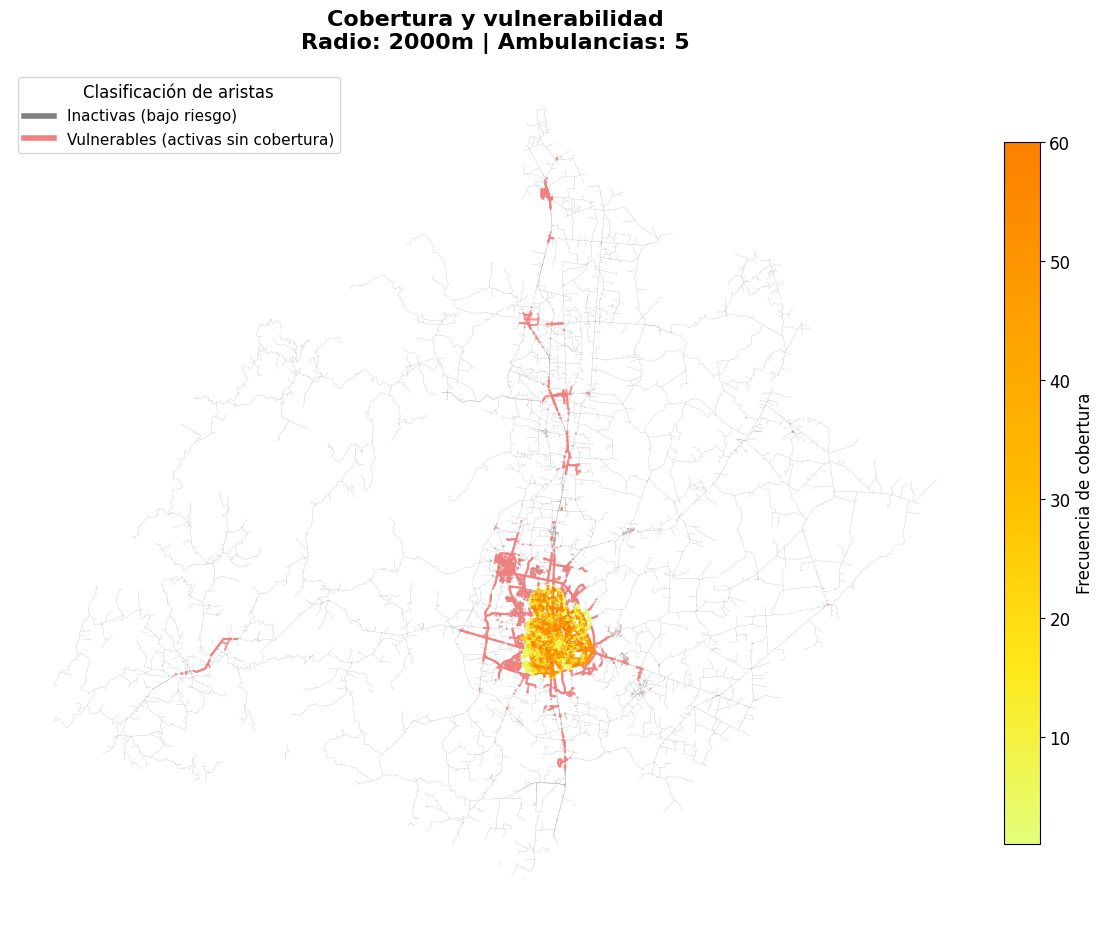

Generando mapa de vulnerabilidad 2/4: Radio 2000m | Ambulancias 6...


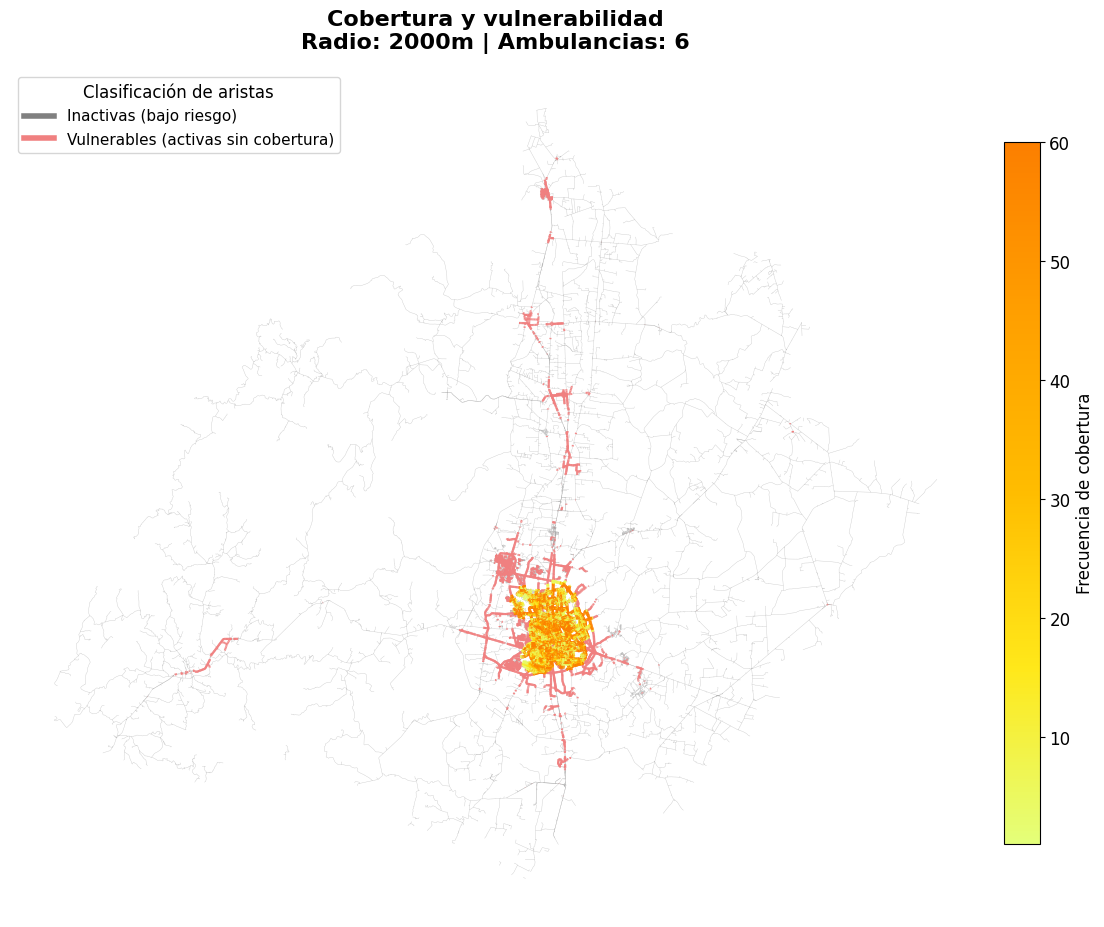

Generando mapa de vulnerabilidad 3/4: Radio 3000m | Ambulancias 5...


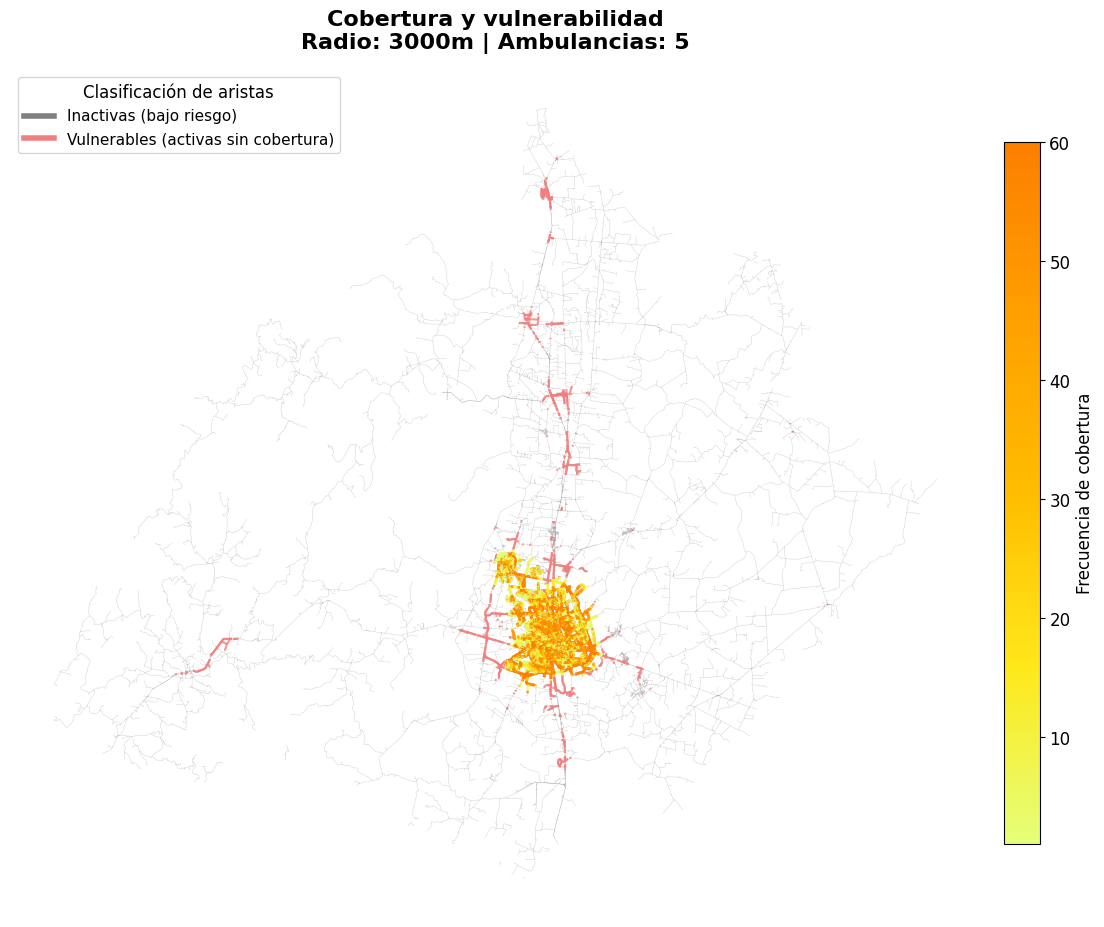

Generando mapa de vulnerabilidad 4/4: Radio 3000m | Ambulancias 6...


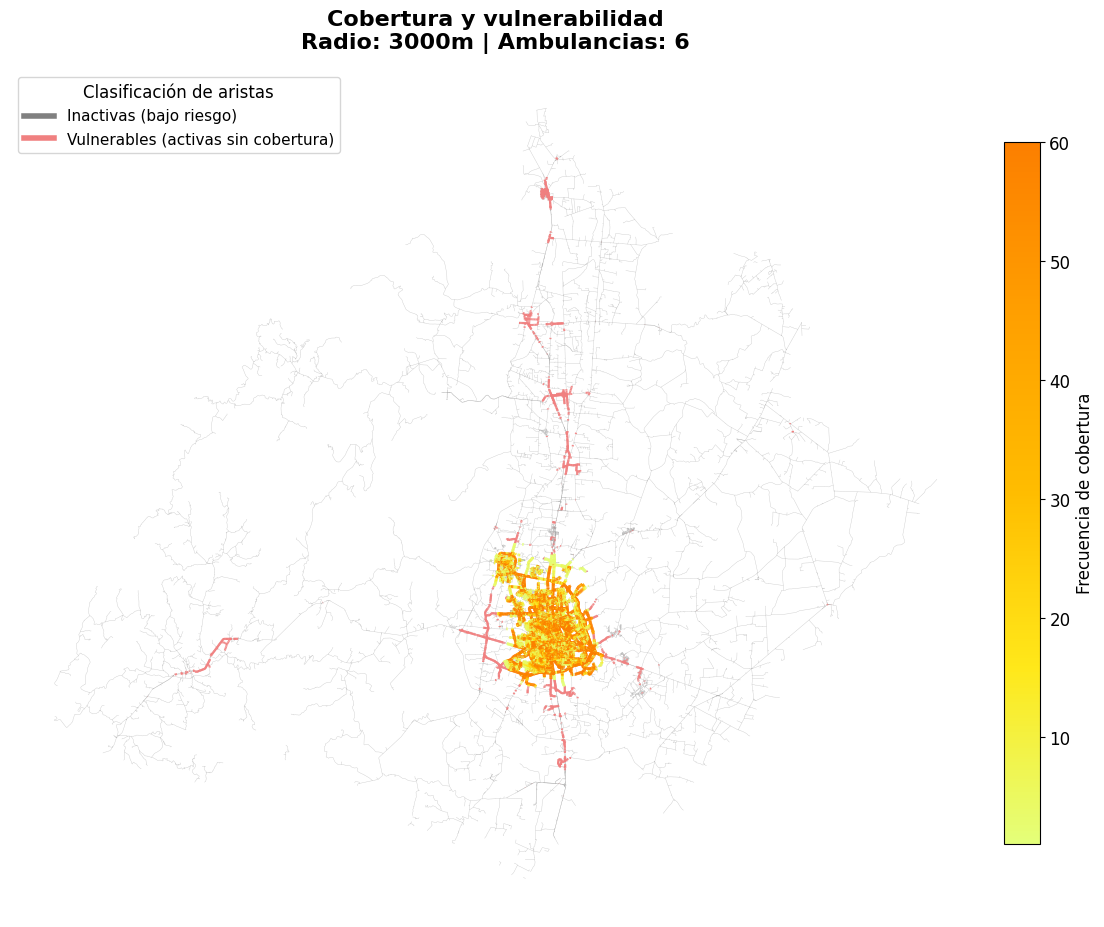

In [9]:
# Definir las combinaciones
configuraciones = [
    (2000, 5),
    (2000, 6),
    (3000, 5),
    (3000, 6)
]

# Líneas personalizadas para la leyenda
custom_lines = [
    Line2D([0], [0], color='grey', lw=4),
    Line2D([0], [0], color='lightcoral', lw=4)
]

# Iterar sobre cada configuración para generar un gráfico individual
for i, (filtro_radio, filtro_amb) in enumerate(configuraciones):
    print(f"Generando mapa de vulnerabilidad {i+1}/4: Radio {filtro_radio}m | Ambulancias {filtro_amb}...")
    
    fig, ax = plt.subplots(figsize=(12, 12))
    frecuencias_cobertura = {id_red: 0 for id_red in gdf_pred['ID_RED']}
    frecuencias_actividad = {id_red: 0 for id_red in gdf_pred['ID_RED']}
    
    df_iterar = df_resultados[
        (df_resultados['Cobertura (m)'] == filtro_radio) & 
        (df_resultados['Ambulancias'] == filtro_amb)
    ].copy()
        
    total_filas = len(df_iterar)
    if total_filas == 0:
        ax.set_title(f"Radio: {filtro_radio}m | Ambulancias: {filtro_amb}\n(Sin datos)", fontsize=16, fontweight='bold')
        ax.axis('off')
        plt.show()
        continue
    
    # Procesamiento espacial
    for idx, fila in df_iterar.reset_index().iterrows():
        id_instancia = fila['ID Instancia']
        cobertura_m = fila['Cobertura (m)']
        ids_ambulancias = fila['IDs Red']
        
        aristas_activas = gdf_pred[gdf_pred[id_instancia] >= umbral].copy()
        for id_a in aristas_activas['ID_RED']:
            frecuencias_actividad[id_a] += 1
            
        if len(ids_ambulancias) == 0:
            continue
            
        aristas_amb = gdf_pred[gdf_pred['ID_RED'].isin(ids_ambulancias)].copy()
        
        if not aristas_amb.empty:
            aristas_amb_proj = aristas_amb.to_crs(aristas_amb.estimate_utm_crs())
            activas_proj = aristas_activas.to_crs(aristas_amb_proj.crs)
            
            puntos_medios = aristas_amb_proj.geometry.interpolate(0.5, normalized=True)
            buffers = puntos_medios.buffer(cobertura_m)
            buffers_gdf = gpd.GeoDataFrame(geometry=buffers, crs=aristas_amb_proj.crs)
            
            cobertura = gpd.sjoin(activas_proj, buffers_gdf, how='inner', predicate='intersects')
            
            ids_cubiertos = cobertura['ID_RED'].unique()
            for id_c in ids_cubiertos:
                frecuencias_cobertura[id_c] += 1

    # Preparar datos para graficar
    gdf_plot = gdf_pred[['ID_RED', 'geometry']].copy()
    gdf_plot['Veces_Activa'] = gdf_plot['ID_RED'].map(frecuencias_actividad)
    gdf_plot['Veces_Cubierta'] = gdf_plot['ID_RED'].map(frecuencias_cobertura)
    
    inactivas = gdf_plot[gdf_plot['Veces_Activa'] == 0]
    vulnerables = gdf_plot[(gdf_plot['Veces_Activa'] > 0) & (gdf_plot['Veces_Cubierta'] == 0)]
    cubiertas = gdf_plot[gdf_plot['Veces_Cubierta'] > 0]
    
    # Graficar capas
    inactivas.plot(ax=ax, color='grey', linewidth=0.3, alpha=0.4)
    
    if not vulnerables.empty:
        vulnerables.plot(ax=ax, color='lightcoral', linewidth=1.5, alpha=0.9)
    
    if not cubiertas.empty:
        cubiertas.plot(
            ax=ax, 
            column='Veces_Cubierta', 
            cmap='Wistia', 
            linewidth=2.0, 
            alpha=0.9,
            legend=True, 
            legend_kwds={
                'label': "Frecuencia de Cobertura", 
                'shrink': 0.6, 
                'pad': 0.02
            }
        )
        
        # Ajustes de la barra de color
        cbar_ax = ax.figure.axes[-1]
        cbar_ax.set_ylabel("Frecuencia de cobertura", fontsize=12)
        cbar_ax.tick_params(labelsize=12)

    # Configuración de título y leyenda para cada gráfico
    ax.set_title(f"Cobertura y vulnerabilidad\nRadio: {filtro_radio}m | Ambulancias: {filtro_amb}", 
                 fontsize=16, fontweight='bold', pad=15)
    
    ax.legend(
        custom_lines, 
        ['Inactivas (bajo riesgo)', 'Vulnerables (activas sin cobertura)'], 
        loc='upper left', 
        fontsize=11, 
        frameon=True,
        title='Clasificación de aristas',
        title_fontsize=12
    )
    
    ax.axis('off')
    plt.tight_layout()
    plt.show()

### 5.2 Estadisticos descriptivos

Se calcularon estadísticos descriptivos para evaluar el comportamiento de las soluciones en términos de tiempo de procesamiento y riesgo cubierto. Se consideran la media, desviación estándar, mínimo, cuartiles, mediana y máximo para las siguientes variables:

- Tiempo de reducción del conjunto de candidatos.
- Tiempo de resolución del solver.
- Porcentaje de riesgo cubierto.

In [10]:
# FUNCIÓN PARA OBTENER ESTADISTICOS SEGÚN COLUMNA
def generar_tabla_estadisticos(df_resultados: pd.DataFrame, columna: str) -> pd.DataFrame:
    """
    Genera una tabla de estadísticos descriptivos para una columna específica,
    agrupando por cobertura y número de ambulancias, y renombrando los resultados al español.

    Parámetros
    ----------
    `df_resultados`: DataFrame con resultados experimentales. 
        Debe incluir al menos:
        - 'Cobertura (m)'
        - 'Ambulancias' (excepto si la columna es 'Tiempo de reducción (s)')
        - La columna numérica sobre la cual se calcularán los estadísticos.
    `columna`: Nombre de la columna sobre la cual se 
        calcularán los estadísticos.

    Retorna
    -------
    `df_est`: pandas.DataFrame
        DataFrame con los estadísticos descriptivos agrupados y renombrados.
        Índice: combinación de 'Cobertura (m)' y, si aplica, 'Ambulancias'.
        Columnas: ['Media', 'Desv. Est.', 'Mín', '1Q', 'Mediana', '3Q', 'Máx'].
    """
    # Agrupar y obtener estadísticas de la columna seleccionada
    df_est = df_resultados.groupby(['Cobertura (m)', 'Ambulancias'])[columna].describe()
    
    # Eliminamos 'count' y renombramos al español
    df_est = df_est.drop(columns='count')
    df_est = df_est.rename(columns={
        'mean': 'Media',
        'std': 'Desv. Est.',
        'min': 'Mín',
        '25%': '1Q',
        '50%': 'Mediana',
        '75%': '3Q',
        'max': 'Máx'
    })
    return df_est

tabla_tiempo_red = generar_tabla_estadisticos(df_resultados, 'Tiempo de reducción (s)')
print("Tabla de estadísticos para el tiempo de reducción (s):")
display(tabla_tiempo_red)
tabla_tiempo_solver = generar_tabla_estadisticos(df_resultados, 'Tiempo del solver (s)')
print("Tabla de estadísticos para el tiempo del solver (s):")
display(tabla_tiempo_solver)
tabla_riesgo = generar_tabla_estadisticos(df_resultados, 'Riesgo cubierto (%)')
print("Tabla de estadísticos para el riesgo cubierto (%):")
display(tabla_riesgo)

Tabla de estadísticos para el tiempo de reducción (s):


Media  Desv. Est.       Mín        1Q   Mediana  \
Cobertura (m) Ambulancias                                                       
2000          5            7.729173    2.040129  4.380464  6.467412  7.264451   
              6            7.729173    2.040129  4.380464  6.467412  7.264451   
3000          5            9.126360    1.647157  7.062079  8.281115  8.743430   
              6            9.126360    1.647157  7.062079  8.281115  8.743430   

                                 3Q        Máx  
Cobertura (m) Ambulancias                       
2000          5            8.914933  13.290490  
              6            8.914933  13.290490  
3000          5            9.434095  15.321059  
              6            9.434095  15.321059

Tabla de estadísticos para el tiempo del solver (s):


Media  Desv. Est.         Mín          1Q  \
Cobertura (m) Ambulancias                                                   
2000          5            290.464145  197.152598   41.547672  178.822469   
              6            442.901063  226.558910  144.831821  299.909689   
3000          5            620.535794  339.437373  139.721388  456.855446   
              6            555.073387  361.309284  148.915258  337.433261   

                              Mediana          3Q          Máx  
Cobertura (m) Ambulancias                                       
2000          5            268.021763  339.360081  1167.575169  
              6            394.454920  484.742651  1359.254066  
3000          5            538.963654  715.271806  2000.625057  
              6            499.310933  651.754296  2118.958305

Tabla de estadísticos para el riesgo cubierto (%):


Media  Desv. Est.        Mín         1Q  \
Cobertura (m) Ambulancias                                                
2000          5            62.450444    1.144543  59.444673  61.710419   
              6            68.462126    1.097702  65.456508  67.822672   
3000          5            85.838705    0.801801  83.427781  85.452091   
              6            89.936746    0.706560  87.644511  89.587517   

                             Mediana         3Q        Máx  
Cobertura (m) Ambulancias                                   
2000          5            62.608639  63.433401  64.153708  
              6            68.703272  69.401049  69.924295  
3000          5            86.085929  86.323020  87.110338  
              6            90.137128  90.386518  91.056223

## 6. Mapas de solución

In [11]:
# Carga de predicciones
gdf_pred = gpd.read_parquet("Generados/predicciones.parquet")
print("Predicciones del RF calibrado cargadas")

# Carga de soluciones del MCLP
df_resultados = pd.read_parquet("Generados/resultados_optimizacion.parquet")
print("Resultados del MCLP cargados")

df_eval = pd.read_csv("Generados/evaluaciones_predictivo.csv")
prob_max = df_eval['Prob_Max'].max()

Predicciones del RF calibrado cargadas
Resultados del MCLP cargados


In [12]:
def graficar_solucion_mclp(
    fila_resultado: pd.Series,
    gdf_pred: gpd.GeoDataFrame,
    umbral_cal: float,
    factor_zoom: float = 0.2,
    max_prob: float = 1.0
) -> None:
    """
    Genera y guarda mapas de la solución del modelo MCLP para una instancia específica,
    mostrando aristas de alto riesgo, ubicaciones óptimas de ambulancias y sus áreas de cobertura.

    Parámetros
    ----------
    `fila_resultado`: Fila del DataFrame de resultados 
        que contiene:
        - 'ID Instancia': identificador de la franja temporal.
        - 'Cobertura (m)': radio de cobertura en metros.
        - 'Ambulancias': número de ambulancias instaladas.
        - 'IDs Red': lista de identificadores de tramos seleccionados.
    `gdf_pred`: GeoDataFrame con predicciones calibradas de probabilidad de accidente.
        Debe incluir:
        - 'ID_RED'
        - 'geometry'
        - columna con nombre igual a 'ID Instancia' (probabilidades).
    `umbral_cal`: Umbral de decisión para clasificar 
        tramos de alto riesgo.
    factor_zoom : Proporción del área total usada para el recorte con zoom
        (default=0.2).
    max_prob : Valor máximo de probabilidad para normalización
        (default=1.0).

    Retorna
    -------
    `None`
        La función no devuelve objetos; genera y guarda directamente las figuras
        en archivos PNG dentro de "Outputs/MCLP".
    """
    id_instancia = fila_resultado['ID Instancia']
    
    # Extraer variables de la fila de resultados
    cobertura_m = fila_resultado['Cobertura (m)']
    n_amb = fila_resultado['Ambulancias']
    lista_ids = fila_resultado['IDs Red'] 
        
    # Predicciones y riesgos
    df_merge = gdf_pred[['ID_RED', 'geometry']].copy()
    df_merge['prob_cal'] = gdf_pred[id_instancia].values
    df_merge['riesgo_alto'] = (df_merge['prob_cal'] >= umbral_cal).astype(int)
    df_merge = df_merge.dropna(subset=['prob_cal'])
    
    # Figura
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Dibujar red de fondo (bajo riesgo)
    df_merge[df_merge['riesgo_alto'] == 0].plot(
        ax=ax, color='grey', linewidth=0.5, alpha=0.4
    )
    
    # Dibujar red activa (alto riesgo calibrado)
    df_merge[df_merge['riesgo_alto'] == 1].plot(
        ax=ax, column='prob_cal', cmap='YlOrRd', linewidth=2.5, vmax=max_prob,
        legend=True, legend_kwds={'label': "Probabilidad de Accidente", 'shrink': 0.6}
    )

    cbar_ax = fig.axes[-1]
    cbar_ax.set_ylabel("Probabilidad de Accidente", fontsize=14)
    cbar_ax.tick_params(labelsize=13)

    # Procesamiento de ambulancias y coberturas
    if len(lista_ids) > 0:
        aristas_ambulancias = df_merge[df_merge['ID_RED'].isin(lista_ids)]
        
        if not aristas_ambulancias.empty:
            # Proyectar a UTM temporalmente para calcular distancias métricas exactas
            aristas_proj = aristas_ambulancias.to_crs(aristas_ambulancias.estimate_utm_crs())
            
            # Obtener los puntos medios de las aristas seleccionadas (Interpolación a 0.5)
            puntos_medios = aristas_proj.geometry.interpolate(0.5, normalized=True)
            
            # Crear los polígonos de cobertura (buffers) en metros
            buffers = puntos_medios.buffer(cobertura_m)
            
            # Reproyectar geometrías de vuelta al CRS original del mapa
            puntos_gdf = gpd.GeoDataFrame(geometry=puntos_medios, crs=aristas_proj.crs).to_crs(df_merge.crs)
            buffers_gdf = gpd.GeoDataFrame(geometry=buffers, crs=aristas_proj.crs).to_crs(df_merge.crs)
            
            # Dibujar el área de cobertura
            buffers_gdf.plot(ax=ax, color='dodgerblue', alpha=0.2, edgecolor='blue', linewidth=1.5, zorder=4)
            
            # Dibujar el marcador de ambulancias
            puntos_gdf.plot(ax=ax, marker='P', color='blue', edgecolor='white', markersize=180, zorder=5)

    # Configuraciones
    texto_titulo = f"Solución MCLP - {id_instancia}"
        
    ax.set_title(texto_titulo, fontsize=19, fontweight='bold', pad=15)
    
    # Construir leyenda personalizada para la cobertura
    elementos_leyenda = [
        Line2D([0], [0], marker='P', color='w', markerfacecolor='blue', markeredgecolor='white', markersize=12, label='Punto de instalación'),
        Patch(facecolor='dodgerblue', edgecolor='blue', alpha=0.3, label='Cobertura')
    ]
    ax.legend(handles=elementos_leyenda, loc='lower right', fontsize=16, framealpha=0.95)

    detalles = [
        f"Cobertura: {fila_resultado['Cobertura (m)']} (m)",
        f"Ambulancias: {fila_resultado['Ambulancias']}",
        f"Aristas cubiertas: {fila_resultado['Aristas cubiertas']} de {fila_resultado['Aristas totales']} ({(fila_resultado['Aristas cubiertas']/fila_resultado['Aristas totales']*100):.2f}%)",
        f"Riesgo cubierto: {fila_resultado['Riesgo cubierto']:.2f} de {fila_resultado['Riesgo total']:.2f}  ({fila_resultado['Riesgo cubierto (%)']:.2f}%)"
    ]

    # Unir todo con saltos de línea
    texto_cuadro = "\n".join(detalles)

    # Imprimir el cuadro de texto en la esquina superior izquierda del mapa
    if texto_cuadro:
        props_caja = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='lightgray')
        ax.text(0.5, 0.99, texto_cuadro, transform=ax.transAxes, 
                fontsize=13, verticalalignment='top', bbox=props_caja, zorder=10)
    
    ax.axis('off')
    
    # Guardado
    ruta_directorio = "Outputs/Soluciones MCLP"
    os.makedirs(ruta_directorio, exist_ok=True)
    plt.tight_layout()
    
    # Extraer límites totales
    minx, miny, maxx, maxy = df_merge.total_bounds
    
    # GUARDADO 1: MAPA GENERAL COMPLETO
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    ruta_general = os.path.join(ruta_directorio, f"{id_instancia}_solucion_{cobertura_m}m_{n_amb}amb.png")
    plt.savefig(ruta_general, dpi=300, bbox_inches='tight')
    
    # GUARDADO 2: MAPA CON ZOOM AL CENTRO
    desplazar_x = 0.073  
    desplazar_y = -0.165 
    
    ancho_total = maxx - minx
    alto_total = maxy - miny
    
    centro_x = ((minx + maxx) / 2) + (ancho_total * desplazar_x)
    centro_y = ((miny + maxy) / 2) + (alto_total * desplazar_y)
    
    ancho_zoom = ancho_total * factor_zoom
    alto_zoom = alto_total * factor_zoom
    
    ax.set_xlim(centro_x - (ancho_zoom / 2), centro_x + (ancho_zoom / 2))
    ax.set_ylim(centro_y - (alto_zoom / 2), centro_y + (alto_zoom / 2))
    
    ruta_zoom = os.path.join(ruta_directorio, f"{id_instancia}_solucion_zoom_{cobertura_m}m_{n_amb}amb.png")
    plt.savefig(ruta_zoom, dpi=300, bbox_inches='tight')
    
    # Cerrar figura de memoria
    plt.close(fig)

In [13]:
actualizar_mapas = False  # Cambiar a False si no deseas regenerar los mapas
if actualizar_mapas:
    print(f"Iniciando generación de mapas de solución para {len(df_resultados)} instancias...\n")

    for index, fila in df_resultados.iterrows():
        id_instancia = fila['ID Instancia']
        cobertura = fila['Cobertura (m)']
        n_amb = fila['Ambulancias']
        print(f"Procesando mapa de solución para: {id_instancia} | {cobertura} m | {n_amb} ambulancias...")
        
        try:
            graficar_solucion_mclp(
                fila_resultado=fila,
                gdf_pred=gdf_pred,
                umbral_cal=umbral,
                max_prob=prob_max,
                factor_zoom=0.19
            )
        except Exception as e:
            print(f" [!] Error al graficar {id_instancia}: {e}")

    print("\nMapas de solución guardados")
else:
    print("Actualización de mapas desactivada. No se generaron nuevos mapas.")

Actualización de mapas desactivada. No se generaron nuevos mapas.
